In [39]:
import scipy.io as spio
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import dm as diffusion_maps
import pandas as pd
from tqdm import tqdm

from scipy.spatial.distance import pdist


from sklearn.model_selection import train_test_split

In [40]:
# plt.style.use('seaborn-white'); 
plt.rc('text', usetex=True); 
plt.rc('xtick', labelsize=16); 
plt.rc('ytick', labelsize=16);
plt.rc('axes', labelsize=20); 
plt.rc('font', family='serif');
plt.rc('font', family='serif') ;
plt.rcParams['image.cmap'] = 'Spectral'

np.random.seed(0)

In [41]:
Phi = np.load('../../Data/Phis_Parameters.npy')[0]

Import_Data = spio.loadmat('../../Data/Model_output.mat', squeeze_me=True)
Parameters = Import_Data['Parameter_values']


In [4]:
Phi = np.array(Phi)
Parameters = np.array(Parameters)

Phi.shape,Parameters.shape

((10000, 6), (10000, 12))

In [5]:
Dict_Parameters = {}
Names_Parameters = ['xdp','x1dp','x2dp','T1d0p',
                    'T2d0p','xqp','x1qp','x2qp',
                    'T1q0p','T2q0p','Hp','Dp']

for i in range(0,len(Names_Parameters)):
    Dict_Parameters[Names_Parameters[i]] = Parameters[:,i]

In [ ]:
Delta_Parameters = []
Delta_Names = []

### 0  deltax1 = (xd - xq)
Delta_Parameters.append(Dict_Parameters['xdp'] - Dict_Parameters['xqp'])
Delta_Names.append(r'$\delta x_1 $')

### 1 deltax2 = (xq - x1q)x
Delta_Parameters.append(Dict_Parameters['xqp'] - Dict_Parameters['x1qp'])
Delta_Names.append(r'$\delta x_2 $')

### 2 deltax3 = (x1q - x1d)
Delta_Parameters.append(Dict_Parameters['x1qp'] - Dict_Parameters['x1dp'])
Delta_Names.append(r'$\delta x_3 $')

### 3 deltax4 = (x1d - x2q)
Delta_Parameters.append(Dict_Parameters['x1dp'] - Dict_Parameters['x2qp'])
Delta_Names.append(r'$\delta x_4 $')

### 4 deltax5 = (x2q - x2d)
Delta_Parameters.append(Dict_Parameters['x2qp'] - Dict_Parameters['x2dp'])
Delta_Names.append(r'$\delta x_5 $')

### 5 deltaTd = (T1d0 - T2d0)
Delta_Parameters.append(Dict_Parameters['T1d0p'] - Dict_Parameters['T2d0p'])
Delta_Names.append(r'$\delta T_d $')

### 6 deltaTq = (T1q0 - T2q0)
Delta_Parameters.append(Dict_Parameters['T1q0p'] - Dict_Parameters['T2q0p'])
Delta_Names.append(r'$\delta T_q $')

### 7 x2d
Delta_Parameters.append(Dict_Parameters['x2dp'])
Delta_Names.append(r"$x_d^{''}$")

### 8 T2d0
Delta_Parameters.append(Dict_Parameters['T2d0p'])
Delta_Names.append(r"$T_{d0}^{''} $")

### 9 T2q0
Delta_Parameters.append(Dict_Parameters['T2q0p'])
Delta_Names.append(r"$T_{q0}^{''} $")

### 10 Hp
Delta_Parameters.append(Dict_Parameters['Hp'])
Delta_Names.append(r'$H$')

### 11 Dp
Delta_Parameters.append(Dict_Parameters['Dp'])
Delta_Names.append(r'$D$')

Delta_Parameters = np.array(Delta_Parameters).T

In [8]:

# Phi_train_norm.shape, Parameters_train_norm.shape
Delta_Parameters[:,4] = np.random.rand(Delta_Parameters.shape[0]) ## to avoid the error message for parameter 4

Phi =((Phi-np.min(Phi,axis=0))/(np.max(Phi,axis=0)-np.min(Phi,axis=0)))
Parameters=((Delta_Parameters-np.min(Delta_Parameters,axis=0))/(np.max(Delta_Parameters,axis=0)-np.min(Delta_Parameters,axis=0)))

Parameters[:,4] = 0 ## make it again zero

Phi_train, Phi_test, Parameters_train, Parameters_test = \
        train_test_split(  Phi, Parameters, test_size=0.2, random_state=0)

### Geometric Harmonics

In [9]:
pw_dists = pdist(Phi_train, "euclidean")
eps_interpolate = np.median(pw_dists**2)

dmap_interpolate = diffusion_maps.SparseDiffusionMaps(points = Phi_train,            
                                                      epsilon = eps_interpolate,             
                                                      num_eigenpairs = 250,
                                                      cut_off = np.inf,  
                                                      renormalization = 0.0,
                                                      normalize_kernel = False)
np.min(dmap_interpolate.eigenvalues)

0.006897619617778979

In [10]:
interp = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                          epsilon = None,
                                                          values = Parameters_train, 
                                                          diffusion_maps = dmap_interpolate)

In [11]:
Parameters_predict_train = interp(Phi_train);
Parameters_predict_test = interp(Phi_test);

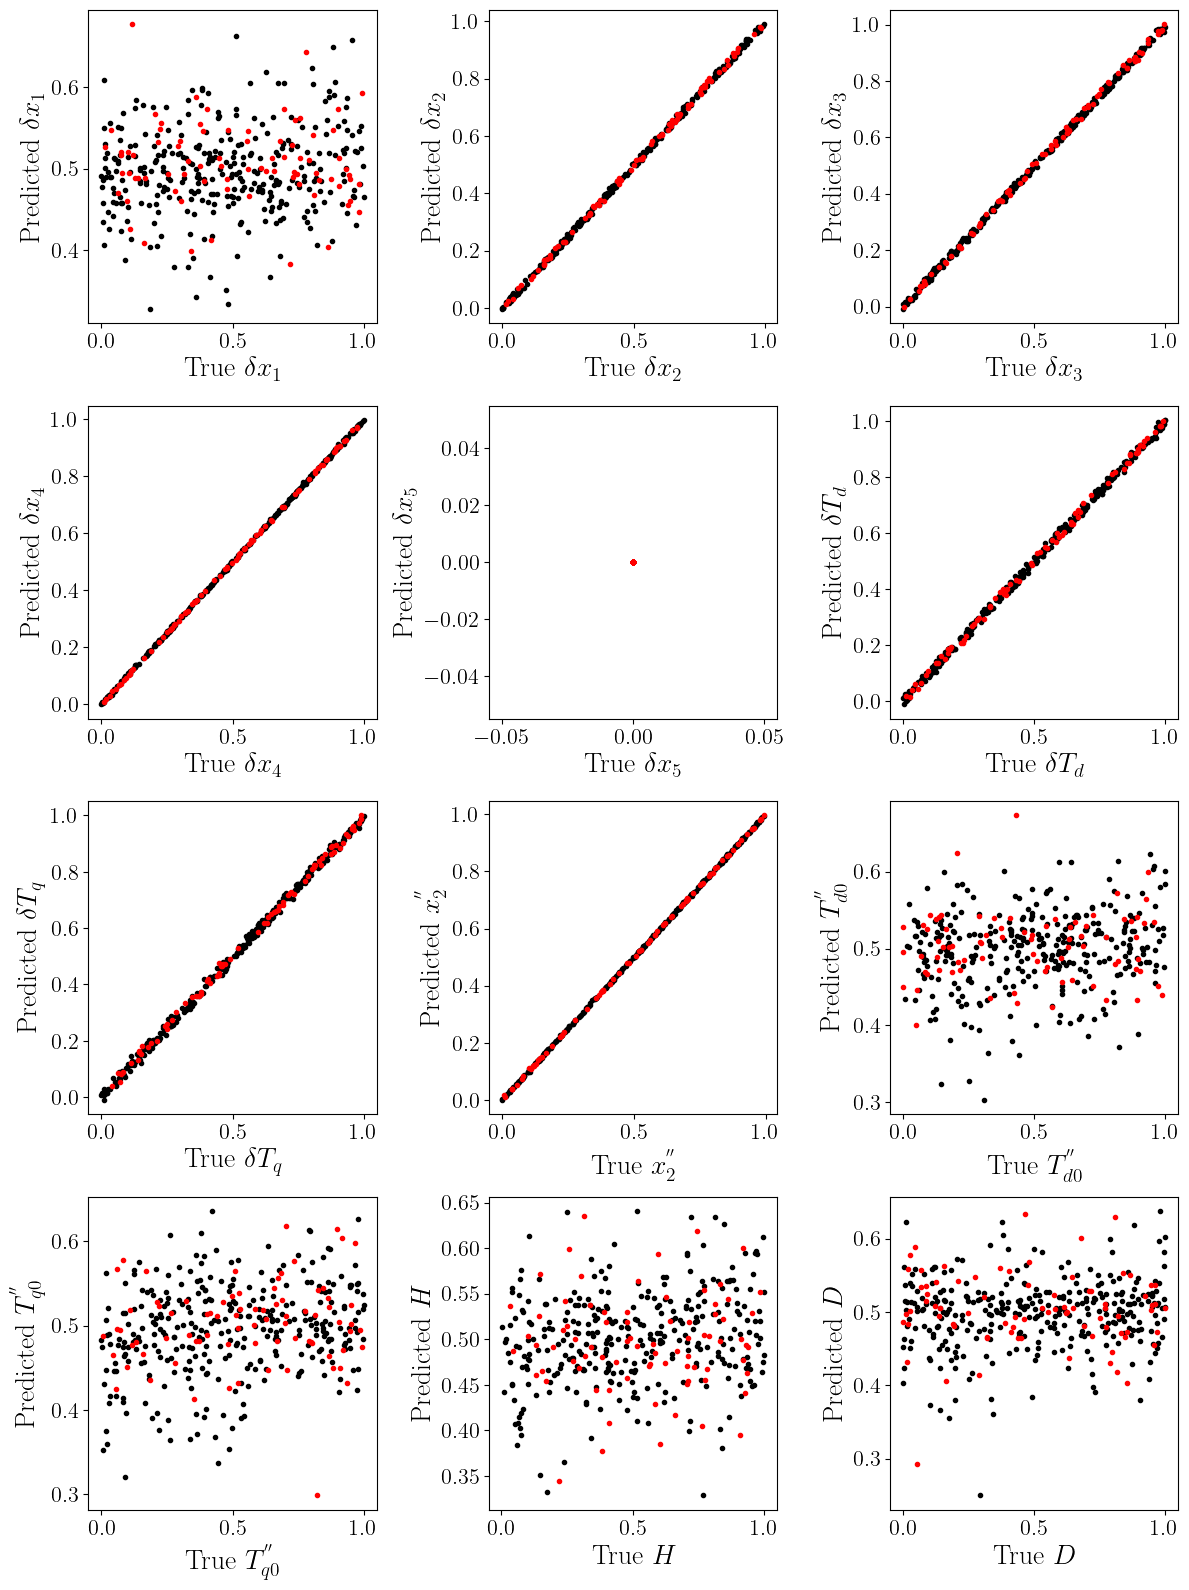

In [12]:
N=25

fig =plt.figure(figsize=(3*4,4*4))
for i in range(0,12):
    ax = fig.add_subplot(4,3,i+1)
    ax.plot(Parameters_train[::N,i],Parameters_predict_train[::N,i],'k.')
    ax.plot(Parameters_test[::N,i],Parameters_predict_test[::N,i],'r.')
    label_x = 'True  ' + Delta_Names[i]
    ax.set_xlabel(label_x)
    label_y = 'Predicted ' + Delta_Names[i]
    ax.set_ylabel(label_y)
    
plt.tight_layout()

plt.savefig('../../Figures/Regression_Phis_.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Regression_Phis_.pdf',bbox_inches='tight')

In [13]:
absolute_pointwise_error = np.abs(Parameters_predict_test - Parameters_test) #/ np.abs(Parameters_test);
absolute_pointwise_error.shape

absolute_pointwise_error = np.delete(absolute_pointwise_error,4,1)
Delta_Names_ =np.delete(Delta_Names,4)

In [14]:
mean_absolute_errors = np.mean(absolute_pointwise_error, axis=0)
mean_absolute_error_per_parameter = [(Delta_Names_[i], mean_absolute_errors[i]) for i in range(11)]

print('Mean Absolute Error Per Parameter:')
for name, error in mean_absolute_error_per_parameter:
    print(f'{name}: {error}')

Mean Absolute Error Per Parameter:
$\delta x_1 $: 0.2507348898228944
$\delta x_2 $: 0.0057764435532998565
$\delta x_3 $: 0.007164460117699719
$\delta x_4 $: 0.002622811599020846
$\delta T_d $: 0.009043440766948185
$\delta T_q $: 0.009570433875134792
$x_2^{''}$: 0.0018326412665740082
$T_{d0}^{''} $: 0.2534466491932702
$T_{q0}^{''} $: 0.25405399791100686
$H$: 0.25316963259808584
$D$: 0.25566633294813645


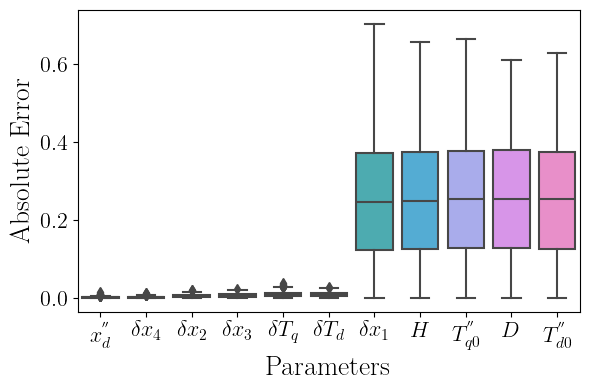

In [38]:
data = pd.DataFrame(absolute_pointwise_error, columns=[
    r'$\delta x_1 $', r'$\delta x_2 $', r'$\delta x_3 $', r'$\delta x_4 $', 
     r'$\delta T_d $', r'$\delta T_q $', r"$x_d^{''}$", 
    r"$T_{d0}^{''} $", r"$T_{q0}^{''} $", r'$H$', r'$D$'
])

## Replace infinite values with NaN and drop them
absolute_pointwise_error[~np.isfinite(absolute_pointwise_error)] = np.nan

# Create a DataFrame to facilitate plotting with seaborn
data = pd.DataFrame(absolute_pointwise_error, columns=[
    r'$\delta x_1 $', r'$\delta x_2 $', r'$\delta x_3 $', r'$\delta x_4 $', 
     r'$\delta T_d $', r'$\delta T_q $', r"$x_d^{''}$", 
    r"$T_{d0}^{''} $", r"$T_{q0}^{''} $", r'$H$', r'$D$'
])

# Drop columns with all NaN values
data = data.dropna(axis=1, how='all')

# Calculate the median of relative errors for each parameter
medians = data.median().sort_values()

# Sort the data based on the medians
sorted_data = data[medians.index]

# Melt the DataFrame for seaborn
melted_data = sorted_data.melt(var_name='Parameters', value_name='Absolute Error')


# Creating the box plots
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111)
sns.boxplot(x='Parameters', y='Absolute Error', data=melted_data, ax=ax)
# Rotating x-axis labels for better readability
ax.set_xticklabels(ax.get_xticklabels())

# Coordinates of rectangle vertices
# in clockwise order
# xs = [-0.3, 5.5, 5.5, -0.3, -0.3]
# ys = [-0.03, -0.03, 0.06, 0.06, -0.03]
# ax.plot(xs, ys, color="red")

# ax.text(2.7, 0.072, "Identifiable Parameters", color="red", fontsize=18, ha="center")
# ax.set_ylim([-0.04,0.75])

plt.tight_layout()
plt.savefig('../../Figures/Power_System_GH_Box_Plots_Parameters.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Power_System_GH_Box_Plots_Parameters.pdf',bbox_inches='tight')

## Check that we the determinant of the Jacobian for the mapping $f:\Phi \to P$ is non-singular

In [16]:
Identifiable_Parameters_train = Parameters_train[:,[1,2,3,5,6,7]] 
Identifiable_Parameters_test = Parameters_test[:,[1,2,3,5,6,7]] 
Identifiable_Names_Delta = Delta_Names[1:3] + Delta_Names[4:8]

In [17]:
pw_dists = pdist(Phi_train, "euclidean")
eps_interpolate = np.median(pw_dists**2)

dmap_interpolate_2 = diffusion_maps.SparseDiffusionMaps(points = Phi_train,            
                                                      epsilon = eps_interpolate,             
                                                      num_eigenpairs = 250,
                                                      cut_off = np.inf,  
                                                      renormalization = 0.0,
                                                      normalize_kernel = False)
np.min(dmap_interpolate_2.eigenvalues)

0.006897619617778979

In [18]:
interp_identifiable_0 = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                          epsilon = None,
                                                          values = Identifiable_Parameters_train[:,0], 
                                                          diffusion_maps = dmap_interpolate_2)


interp_identifiable_1 = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                          epsilon = None,
                                                          values = Identifiable_Parameters_train[:,1], 
                                                          diffusion_maps = dmap_interpolate_2)

interp_identifiable_2 = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                            epsilon = None,
                                                            values = Identifiable_Parameters_train[:,2], 
                                                            diffusion_maps = dmap_interpolate_2)

interp_identifiable_3 = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                            epsilon = None,
                                                            values = Identifiable_Parameters_train[:,3], 
                                                            diffusion_maps = dmap_interpolate_2)

interp_identifiable_4 = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                            epsilon = None,
                                                            values = Identifiable_Parameters_train[:,4], 
                                                            diffusion_maps = dmap_interpolate_2)

interp_identifiable_5 = diffusion_maps.GeometricHarmonicsInterpolator(points = Phi_train,
                                                            epsilon = None,
                                                            values = Identifiable_Parameters_train[:,5], 
                                                            diffusion_maps = dmap_interpolate_2)

In [19]:
Identifiable_Parameter_0_predict_train = interp_identifiable_0(Phi_train);
Identifiable_Parameter_1_predict_train = interp_identifiable_1(Phi_train);
Identifiable_Parameter_2_predict_train = interp_identifiable_2(Phi_train);
Identifiable_Parameter_3_predict_train = interp_identifiable_3(Phi_train);
Identifiable_Parameter_4_predict_train = interp_identifiable_4(Phi_train);
Identifiable_Parameter_5_predict_train = interp_identifiable_5(Phi_train);

Identifiable_Parameter_0_predict_test = interp_identifiable_0(Phi_test);
Identifiable_Parameter_1_predict_test = interp_identifiable_1(Phi_test);
Identifiable_Parameter_2_predict_test = interp_identifiable_2(Phi_test);
Identifiable_Parameter_3_predict_test = interp_identifiable_3(Phi_test);
Identifiable_Parameter_4_predict_test = interp_identifiable_4(Phi_test);
Identifiable_Parameter_5_predict_test = interp_identifiable_5(Phi_test);

Identifiable_Parameters_Train_List = [Identifiable_Parameter_0_predict_train,Identifiable_Parameter_1_predict_train,
                                        Identifiable_Parameter_2_predict_train,Identifiable_Parameter_3_predict_train,
                                        Identifiable_Parameter_4_predict_train,Identifiable_Parameter_5_predict_train]

Identifiable_Parameters_Test_List = [Identifiable_Parameter_0_predict_test,Identifiable_Parameter_1_predict_test,
                                        Identifiable_Parameter_2_predict_test,Identifiable_Parameter_3_predict_test,
                                        Identifiable_Parameter_4_predict_test,Identifiable_Parameter_5_predict_test]


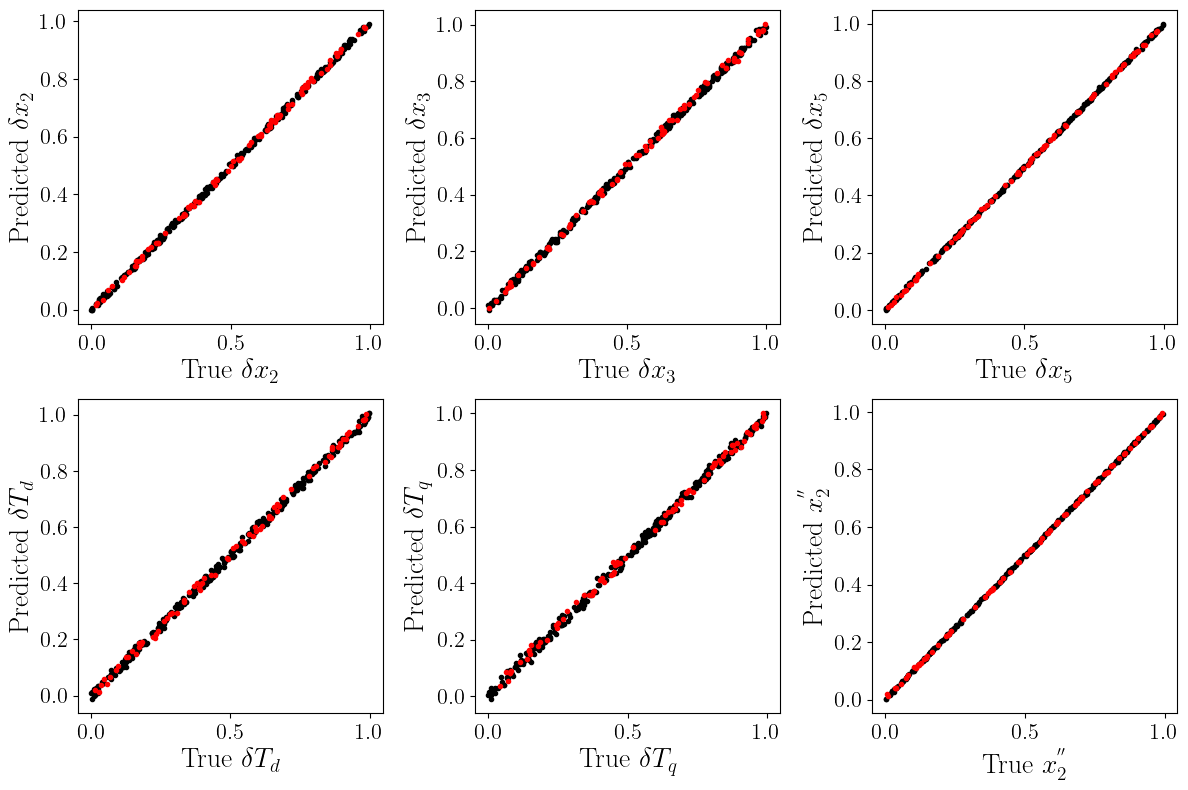

In [20]:
N = 25

fig =plt.figure(figsize=(3*4,2*4))
for i in range(0,6):
    ax = fig.add_subplot(2,3,i+1)
    ax.plot(Identifiable_Parameters_train[::N,i],Identifiable_Parameters_Train_List[i][::N],'k.')
    ax.plot(Identifiable_Parameters_test[::N,i],Identifiable_Parameters_Test_List[i][::N],'r.')
    label_x = 'True  ' + Identifiable_Names_Delta[i]
    ax.set_xlabel(label_x)
    label_y = 'Predicted ' + Identifiable_Names_Delta[i]
    ax.set_ylabel(label_y)

plt.tight_layout()

plt.savefig('../../Figures/Power_Systems_GH_Parity_Plots.png',bbox_inches='tight')
plt.savefig('../../Figures/Power_Systems_GH_Parity_Plots.pdf',bbox_inches='tight')

In [21]:
def Jacobian (Phi_i):
    J = np.zeros((6,6))
    J[:,0] = interp_identifiable_0.gradient(Phi_i)
    J[:,1] = interp_identifiable_1.gradient(Phi_i)
    J[:,2] = interp_identifiable_2.gradient(Phi_i)
    J[:,3] = interp_identifiable_3.gradient(Phi_i)
    J[:,4] = interp_identifiable_4.gradient(Phi_i)
    J[:,5] = interp_identifiable_5.gradient(Phi_i)
    return np.linalg.det(J)

In [22]:
Deteterminant_Jacobian = np.zeros(Phi_test.shape[0])
for i in tqdm(range(0,Phi_test.shape[0])):
    Deteterminant_Jacobian[i] = Jacobian(Phi_test[i,:])


  0%|          | 0/2000 [00:00<?, ?it/s]

100%|██████████| 2000/2000 [05:08<00:00,  6.49it/s]


In [23]:
np.min(Deteterminant_Jacobian),np.max(Deteterminant_Jacobian)

(7.0252894679668225, 15.923367037234327)

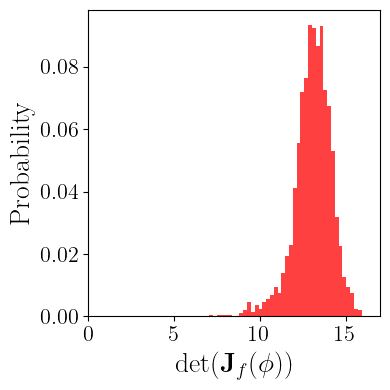

In [24]:
fig =plt.figure(figsize=(4,4))
ax = fig.add_subplot(111)
sns.histplot(Deteterminant_Jacobian, bins=40, kde=False,stat='probability',color ='red',fill=True,linewidth=0,zorder=0, ax=ax) 
ax.set_xlabel('det' + r'$(\mathbf{J}_f(\mathbf{\phi}))$')
ax.set_ylabel('Probability')
ax.set_xlim([0,17])
plt.tight_layout()


plt.savefig('../../Figures/Power_Systems_Jacobian_Phis.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Power_Systems_Jacobian_Phis.pdf',bbox_inches='tight')

## Now! Check that we the determinant of the Jacobian for the mapping $f:P \to \Phi$ is non-singular

In [25]:
pw_dists = pdist(Identifiable_Parameters_train, "euclidean")
eps_interpolate = np.median(pw_dists**2)

dmap_interpolate_3 = diffusion_maps.SparseDiffusionMaps(points = Identifiable_Parameters_train,            
                                                      epsilon = eps_interpolate,             
                                                      num_eigenpairs = 250,
                                                      cut_off = np.inf,  
                                                      renormalization = 0.0,
                                                      normalize_kernel = False)
np.min(dmap_interpolate_3.eigenvalues)

0.007028112109879174

In [26]:
Identifiable_Parameters_train.shape, Phi_train.shape

((8000, 6), (8000, 6))

In [27]:
interp_identifiable_v0 = diffusion_maps.GeometricHarmonicsInterpolator(points = Identifiable_Parameters_train,
                                                          epsilon = None,
                                                          values = Phi_train[:,0], 
                                                          diffusion_maps = dmap_interpolate_3)


interp_identifiable_v1 = diffusion_maps.GeometricHarmonicsInterpolator(points = Identifiable_Parameters_train,
                                                          epsilon = None,
                                                          values = Phi_train[:,1], 
                                                          diffusion_maps = dmap_interpolate_3)

interp_identifiable_v2 = diffusion_maps.GeometricHarmonicsInterpolator(points = Identifiable_Parameters_train,
                                                            epsilon = None,
                                                            values = Phi_train[:,2], 
                                                            diffusion_maps = dmap_interpolate_3)

interp_identifiable_v3 = diffusion_maps.GeometricHarmonicsInterpolator(points = Identifiable_Parameters_train,
                                                            epsilon = None,
                                                            values = Phi_train[:,3], 
                                                            diffusion_maps = dmap_interpolate_3)

interp_identifiable_v4 = diffusion_maps.GeometricHarmonicsInterpolator(points = Identifiable_Parameters_train,
                                                            epsilon = None,
                                                            values = Phi_train[:,4], 
                                                            diffusion_maps = dmap_interpolate_3)

interp_identifiable_v5 = diffusion_maps.GeometricHarmonicsInterpolator(points = Identifiable_Parameters_train,
                                                            epsilon = None,
                                                            values = Phi_train[:,5], 
                                                            diffusion_maps = dmap_interpolate_3)

In [28]:
Phi_0_predict_train = interp_identifiable_v0(Identifiable_Parameters_train);
Phi_1_predict_train = interp_identifiable_v1(Identifiable_Parameters_train);
Phi_2_predict_train = interp_identifiable_v2(Identifiable_Parameters_train);
Phi_3_predict_train = interp_identifiable_v3(Identifiable_Parameters_train);
Phi_4_predict_train = interp_identifiable_v4(Identifiable_Parameters_train);
Phi_5_predict_train = interp_identifiable_v5(Identifiable_Parameters_train);


Phi_0_predict_test = interp_identifiable_v0(Identifiable_Parameters_test);
Phi_1_predict_test = interp_identifiable_v1(Identifiable_Parameters_test);
Phi_2_predict_test = interp_identifiable_v2(Identifiable_Parameters_test);
Phi_3_predict_test = interp_identifiable_v3(Identifiable_Parameters_test);
Phi_4_predict_test = interp_identifiable_v4(Identifiable_Parameters_test);
Phi_5_predict_test = interp_identifiable_v5(Identifiable_Parameters_test);

Phi_Train_Predict_List = [Phi_0_predict_train,Phi_1_predict_train,Phi_2_predict_train,Phi_3_predict_train,Phi_4_predict_train,Phi_5_predict_train]
Phi_Test_Predict_List = [Phi_0_predict_test,Phi_1_predict_test,Phi_2_predict_test,Phi_3_predict_test,Phi_4_predict_test,Phi_5_predict_test]

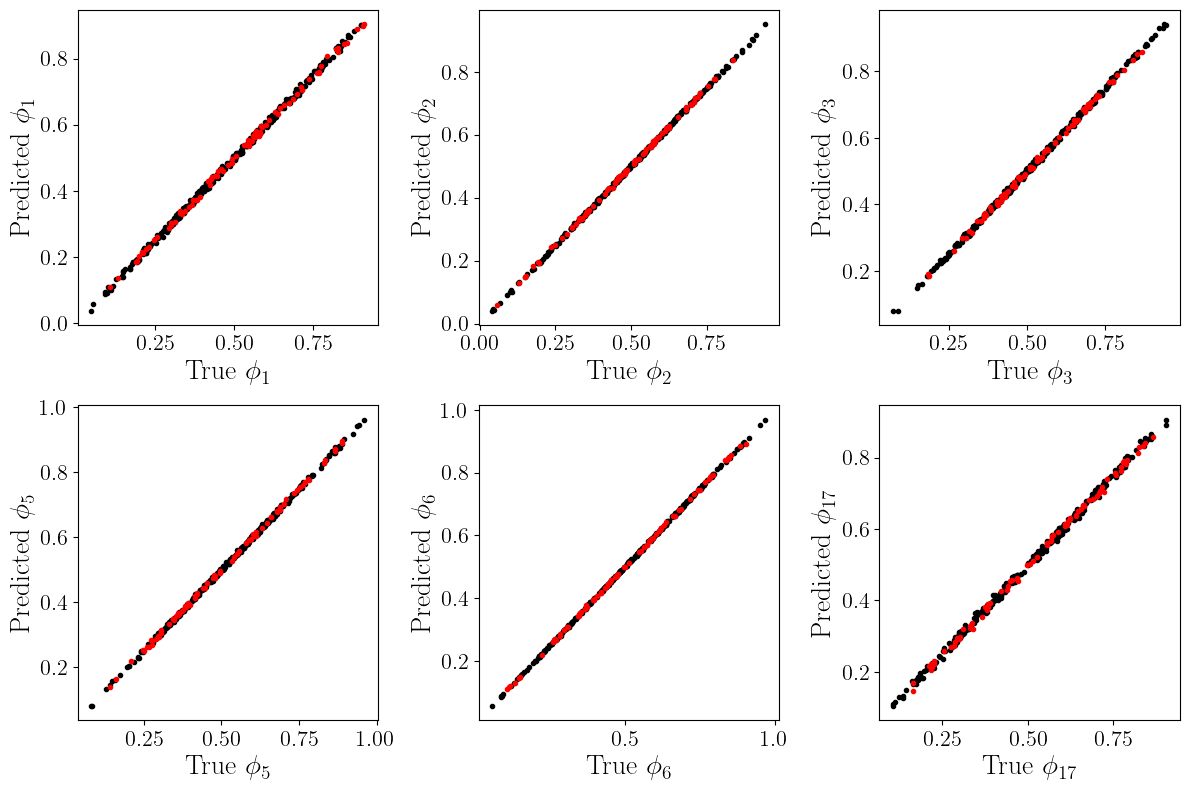

In [29]:
Names_Phis = ['$\\phi_1$', '$\\phi_2$', '$\\phi_3$', '$\\phi_5$', '$\\phi_6$', '$\\phi_{17}$']
N = 25
fig =plt.figure(figsize=(3*4,2*4))
for i in range(0,6):
    ax = fig.add_subplot(2,3,i+1)
    ax.plot(Phi_train[::N,i],Phi_Train_Predict_List[i][::N],'k.')
    ax.plot(Phi_test[::N,i],Phi_Test_Predict_List[i][::N],'r.')
    label_x = 'True  ' + Names_Phis[i]
    ax.set_xlabel(label_x)
    label_y = 'Predicted ' + Names_Phis[i]
    ax.set_ylabel(label_y)

    plt.tight_layout()

plt.savefig('../../Figures/Power_Systems_GH_Parity_Plots_Phis.png',bbox_inches='tight')
plt.savefig('../../Figures/Power_Systems_GH_Parity_Plots_Phis.pdf',bbox_inches='tight')

In [30]:
Phi_Test_Predict =np.array(Phi_Test_Predict_List).T

In [31]:
test_errors = np.abs(Phi_test - Phi_Test_Predict)

In [32]:
mean_absolute_errors_phis = np.mean(test_errors, axis=0)
mean_absolute_error_per_phi = [(Names_Phis[i], mean_absolute_errors_phis[i]) for i in range(6)]

print('Mean Absolute Error Per Phi:')
for name, error in mean_absolute_error_per_phi:
    print(f'{name}: {error}')

Mean Absolute Error Per Phi:
$\phi_1$: 0.005751156984040428
$\phi_2$: 0.0028141310668424947
$\phi_3$: 0.004748399827929572
$\phi_5$: 0.0037091889402545183
$\phi_6$: 0.001816325938074901
$\phi_{17}$: 0.006193190985300158


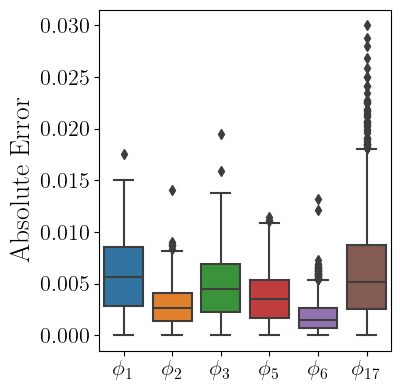

In [33]:
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111)
sns.boxplot(data=test_errors, ax=ax)

# Setting x-axis labels
ax.set_xticklabels(Names_Phis)

# Setting the y-axis label
ax.set_ylabel('Absolute Error')

# Adding a title

# Rotating x-axis labels for better readability
ax.set_xticklabels(ax.get_xticklabels())

# Showing the plot
plt.tight_layout()


plt.savefig('../../Figures/Power_System_GH_Box_Plots_Phis.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Power_System_GH_Box_Plots_Phis.pdf',bbox_inches='tight')

In [34]:
def Jacobian_inverse (Parameters_i):
    J = np.zeros((6,6))
    J[:,0] = interp_identifiable_v0.gradient(Parameters_i)
    J[:,1] = interp_identifiable_v1.gradient(Parameters_i)
    J[:,2] = interp_identifiable_v2.gradient(Parameters_i)
    J[:,3] = interp_identifiable_v3.gradient(Parameters_i)
    J[:,4] = interp_identifiable_v4.gradient(Parameters_i)
    J[:,5] = interp_identifiable_v5.gradient(Parameters_i)
    return np.linalg.det(J)

In [35]:
Deteterminant_Jacobian_inverse = np.zeros(Parameters_test.shape[0])
for i in tqdm(range(0,Parameters_test.shape[0])):
    Deteterminant_Jacobian_inverse[i] = Jacobian_inverse(Identifiable_Parameters_test[i,:])


100%|██████████| 2000/2000 [05:08<00:00,  6.49it/s]


In [36]:
np.min(Deteterminant_Jacobian_inverse),np.max(Deteterminant_Jacobian_inverse)

(0.04597244291004207, 0.08925947904895982)

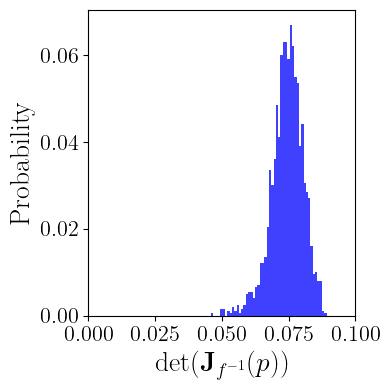

In [37]:
fig =plt.figure(figsize=(4,4))
ax = fig.add_subplot(111)
sns.histplot(Deteterminant_Jacobian_inverse, bins=50,stat='probability',color ='blue',fill=True,linewidth=0,zorder=0)
ax.set_xlabel('det' + r'$(\mathbf{J}_{f^{-1}}({p}))$')
ax.set_ylabel('Probability')
ax.set_xlim([0,0.1])
plt.tight_layout()

plt.savefig('../../Figures/Power_Systems_Jacobian_Parameters.png',dpi=300,bbox_inches='tight')
plt.savefig('../../Figures/Power_Systems_Jacobian_Parameters.pdf',bbox_inches='tight')